# 4. Effective parameters and tunnelling amplitudes

**Thesis:** Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona (2026). [Read the thesis](https://hdl.handle.net/2445/231684).

**Reading guide:** Sections 4.1–4.4, pp. 29–33; Figures 6–7. Page numbers below are the printed thesis pages. Equations retain the thesis notation and numbering; an extract from a longer equation is identified as an extract.

**Evidence:** the physics text describes the theoretical model and numerical calculations reported in the thesis. It does not add experimental results or new derivations. Calculation cells come from the original uploaded scripts at commit `22959963191fcbc4d283ec4b272b506ad6dd979b`. Short setup cells only handle notebook execution and display.

Read each explanation, then run its code cell. Source discrepancies and notebook adaptations are labelled explicitly.

**Notebook setup / execution control:** Imports used by the scripts; locate the repository data directory and display plots inline.

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
from timeit import default_timer as timer
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'scripts').is_dir() and (p / 'data').is_dir())
DATA = ROOT / 'data'

## 1. Effective chemical potential and interaction

**Thesis source:** Sections 4.1–4.2, p. 29, Eqs. (58), (64)–(65). Explanations below paraphrase this passage.

The thesis defines the effective parameters using the low-occupation addition energies, independently of whether all diagonal matching conditions hold:
$$\mu_{\mathrm{eff}}=E_{01}-E_{00}=3\Delta_1-\Delta_2-S_1,\qquad
U_{\mathrm{eff}}=E_{02}-2E_{01}+E_{00}=-4\Delta_1+2\Delta_2-\Delta_3+3S_1.\tag{65}$$
Here $E_{00},E_{01},E_{02}$ are the diagonal entries in Eq. (64); the $\Delta_i$ and $S_i$ abbreviate the shifts defined in Eq. (58). These are the thesis's definitions. No added chemical-potential convention is substituted.

**Symbols — Table 1, Section 3.3, and Figure 3.**

| Thesis symbol | Meaning | Script name |
|---|---|---|
| $C_{ij}$ | Interaction-shift parameters | `C00`, `C01`, … |
| $\Omega_\alpha,\Omega_\beta$ | Coupling amplitudes | `Om_a`, `Om_b` |
| $\omega'$ | Modulation frequency | `WP` or `wp` |
| $A$ | Modulation amplitude | `A` |
| $\kappa=A/\omega'$ | Modulation index | `kap` or `kappa` |
| $\widetilde\nu_j$ | Floquet detuning at site $j$ | `nu`, `nt0`, `nt1` |
| $J_\ell(\kappa)$ | Bessel function of order $\ell$ | `jv(ells, ...)` |
| $L$, $N$ | Number of sites; total occupation | `L`, `N` |

**Source convention:** the thesis and original scripts label these numerical energies/rates in MHz and use $\hbar=1$ for evolution. Their original labels and numbers are retained here. **Source discrepancy:** the `heff2_states.py` header equates MHz with rad/µs, whereas thesis Appendix B writes $\omega'/(2\pi)=40$ MHz. This notebook reproduces the supplied convention; it does not resolve that frequency conversion or introduce a replacement time variable.

**Code source:** [`amplitudes_vs_muU_thesis.py`, lines 30–53](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/amplitudes_vs_muU_thesis.py#L30-L53).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [2]:
import numpy as np
import math
from scipy.special import jv, jn_zeros
from scipy.optimize import brentq

C00, C01, C11 = 0.0, 20.0, 15.0
C02 = 2.0 * C11
C12, C22 = 45.0, 55.0
wp = 40.0
N_RES = 1
nu = 2 * C11 - C02 - N_RES * wp
ells = np.arange(-80, 81)

D1 = 1.0 / (C01 - 2 * C00)
D2 = 1.0 / (2 * C11 - C01)
D3 = 1.0 / (C12 - C02)
K1 = abs(D1 - D2)
K2 = abs(D2 - D3)
A_ = 3 * D1 - D2
B_ = 4 * D1 + D3 - 2 * D2

KAPPAS = [0.8, 1.2, 2.0]
KMAIN = 1.2
COL = {0.8: '#7fb3d5', 1.2: '#12395e', 2.0: '#2e86c1'}

## 2. Sideband sums and the ratio

**Thesis source:** Section 4.2, p. 30, Eqs. (69)–(71); Section 4.4, p. 33. Explanations below paraphrase this passage.

The thesis introduces
$$r\equiv\frac{\Omega_\beta^2}{\Omega_\alpha^2},\qquad
\Sigma\equiv\sum_{\ell=-\infty}^{\infty}\frac{J_\ell^2(\kappa)}{C_{02}-C_{01}+\widetilde\nu+\ell\omega'}.\tag{69}$$
The geometry factors are
$$a=\frac{3}{C_{01}-2C_{00}}-\frac{1}{2C_{11}-C_{01}},\qquad
b=\frac{4}{C_{01}-2C_{00}}+\frac{1}{C_{12}-C_{02}}-\frac{2}{2C_{11}-C_{01}}.\tag{70}$$
Writing $x=r\Sigma(\kappa)$ gives
$$\frac{\mu_{\mathrm{eff}}}{U_{\mathrm{eff}}}=\frac{a-x}{3x-b}.\tag{71}$$
The text identifies the pole $x=b/3$, zero $x=a$, value $-a/b$ at $x=0$, and limit $-1/3$ as $|x|\to\infty$.

**Code reading:** the uploaded script names $a,b$ as `A_`, `B_`; `D1`, `D2`, `D3` are inverse denominators, not the thesis's Rabi-weighted $\Delta_i$. `Sigma4` computes the sum inside the magnitude of the last line of Eq. (75).

**Code source:** [`amplitudes_vs_muU_thesis.py`, lines 56–57](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/amplitudes_vs_muU_thesis.py#L56-L57).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [3]:
def Sigma(k):
  return float(np.sum(jv(ells, k)**2 / (C02 - C01 + nu + ells * wp)))

**Code source:** [`amplitudes_vs_muU_thesis.py`, lines 60–63](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/amplitudes_vs_muU_thesis.py#L60-L63).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [4]:
def Sigma4(k):
  return float(np.sum(jv(ells, k)**2
                      * (1.0 / (C12 - 2 * C11 + nu + ells * wp)
                         - 1.0 / (2 * C22 - C12 + nu + ells * wp))))

**Code source:** [`amplitudes_vs_muU_thesis.py`, lines 66–67](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/amplitudes_vs_muU_thesis.py#L66-L67).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [5]:
def muU_x(x):
  return (A_ - x) / (3.0 * x - B_)

## 3. The tunnelling magnitudes

**Thesis source:** Sections 4.3–4.4, p. 33, Eqs. (74)–(76); Section 4.2, pp. 30–31. Explanations below paraphrase this passage.

For the equal-detuning resonance condition of Eq. (74), the thesis gives
$$A_1=\Omega_\alpha^2\left|\frac{1}{C_{01}-2C_{00}}-\frac{1}{2C_{11}-C_{01}}\right|=J,$$
$$A_2=A_3=\Omega_\alpha\Omega_\beta\left|\frac{1}{2C_{11}-C_{01}}-\frac{1}{C_{12}-C_{02}}\right||J_N(\kappa)|=J\sqrt2,$$
$$A_4=\Omega_\beta^2\left|\sum_{\ell=-\infty}^{\infty}J_\ell^2(\kappa)
\left(\frac{1}{C_{12}-2C_{11}+\widetilde\nu+\ell\omega'}-\frac{1}{2C_{22}-C_{12}+\widetilde\nu+\ell\omega'}\right)\right|=2J.\tag{75}$$
The right-hand equalities are the target matching conditions. They are not automatically satisfied by the reference parameters. Here $N$ is the integer resonance order of Eq. (76), written `N_RES` in the script; it is not the chain's total occupation.

The following source-code report evaluates the ratio, reference magnitudes, and Bessel-zero locations.

**Code source:** [`amplitudes_vs_muU_thesis.py`, lines 70–105](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/amplitudes_vs_muU_thesis.py#L70-L105).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [6]:
# sign change of Sigma: this is what opens the otherwise forbidden window
ks = np.linspace(0.05, 6.0, 6000)
sg = [Sigma(k) for k in ks]
kz = [brentq(Sigma, ks[i], ks[i + 1]) for i in range(len(ks) - 1)
      if sg[i] * sg[i + 1] < 0]

print('=' * 76)
print('A_1, A_2 = A_3, A_4 versus mu_eff/U_eff   (thesis figure)')
print('=' * 76)
print('a = %.6f /MHz, b = %.6f /MHz' % (A_, B_))
print('pole  x = b/3 = %.6f /MHz;  zero x = a = %.6f /MHz;  limit -1/3'
      % (B_ / 3, A_))
print('x -> 0 gives mu/U = a/(-b) = %.6f' % (A_ / -B_))
print()
print('For Sigma > 0 the reachable set is (-inf, -3/4] U (-1/3, +inf):')
print('   the window -3/4 < mu_eff/U_eff < -1/3 is NOT reachable.')
print('For Sigma < 0 that window IS swept, since x < 0 then runs 0 -> -inf.')
print('Sigma changes sign at kappa = %s' % ', '.join('%.4f' % z for z in kz))
print('   -> Sigma(0.8) = %+.6f (negative), Sigma(1.2) = %+.6f (positive)'
      % (Sigma(0.8), Sigma(1.2)))
print()
print('operating point Om_a = Om_b = 1, kappa = %.1f:' % KMAIN)
print('   mu_eff/U_eff = %+.6f' % muU_x(Sigma(KMAIN)))
print('   A_1 = %.6f, A_2 = A_3 = %.6f, A_4 = %.6f MHz'
      % (K1, K2 * abs(jv(N_RES, KMAIN)), abs(Sigma4(KMAIN))))
print('   ratios to A_1: 1, %.4f, %.4f   (targets 1, %.4f, 2)'
      % (K2 * abs(jv(N_RES, KMAIN)) / K1, abs(Sigma4(KMAIN)) / K1, math.sqrt(2)))
z1 = jn_zeros(N_RES, 1)[0]
k4 = [brentq(Sigma4, ks[i], ks[i + 1]) for i in range(len(ks) - 1)
      if Sigma4(ks[i]) * Sigma4(ks[i + 1]) < 0]
print()
print('zeros that switch a channel off: A_2 = A_3 = 0 at kappa = %.4f '
      '(first zero of J_%d);' % (z1, N_RES))
print('   A_4 = 0 at kappa = %s (zeros of Sigma_4)'
      % ', '.join('%.4f' % z for z in k4[:3]))
print('=' * 76)

A_1, A_2 = A_3, A_4 versus mu_eff/U_eff   (thesis figure)
a = 0.050000 /MHz, b = 0.066667 /MHz
pole  x = b/3 = 0.022222 /MHz;  zero x = a = 0.050000 /MHz;  limit -1/3
x -> 0 gives mu/U = a/(-b) = -0.750000

For Sigma > 0 the reachable set is (-inf, -3/4] U (-1/3, +inf):
   the window -3/4 < mu_eff/U_eff < -1/3 is NOT reachable.
For Sigma < 0 that window IS swept, since x < 0 then runs 0 -> -inf.
Sigma changes sign at kappa = 1.0585, 3.4910, 4.2841
   -> Sigma(0.8) = -0.012149 (negative), Sigma(1.2) = +0.006550 (positive)

operating point Om_a = Om_b = 1, kappa = 1.2:
   mu_eff/U_eff = -0.924143
   A_1 = 0.050000, A_2 = A_3 = 0.016610, A_4 = 0.010120 MHz
   ratios to A_1: 1, 0.3322, 0.2024   (targets 1, 1.4142, 2)



zeros that switch a channel off: A_2 = A_3 = 0 at kappa = 3.8317 (first zero of J_1);
   A_4 = 0 at kappa = 1.3292, 3.3175, 4.5008 (zeros of Sigma_4)


## 4. Amplitudes against the effective ratio

**Thesis source:** Section 4.2, pp. 30–31, Figure 6; Section 2.2. Explanations below paraphrase this passage.

Figure 6 varies the coupling that changes each channel: $\Omega_\alpha$ for $A_1$, and $\Omega_\beta$ for $A_2=A_3$ and $A_4$. The curves split at the pole of Eq. (71). The shaded window is discussed in Eq. (72). The original source sweep ranges and plotting routines are retained. These are curves of the effective-model formulas; the dispersive assumption remains the one stated in Section 2.2.

**Code source:** [`amplitudes_vs_muU_thesis.py`, lines 108–176](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/amplitudes_vs_muU_thesis.py#L108-L176).

**Notebook changes:** Original formula calculations, sweep ranges and plotting code; inline display replaces export.

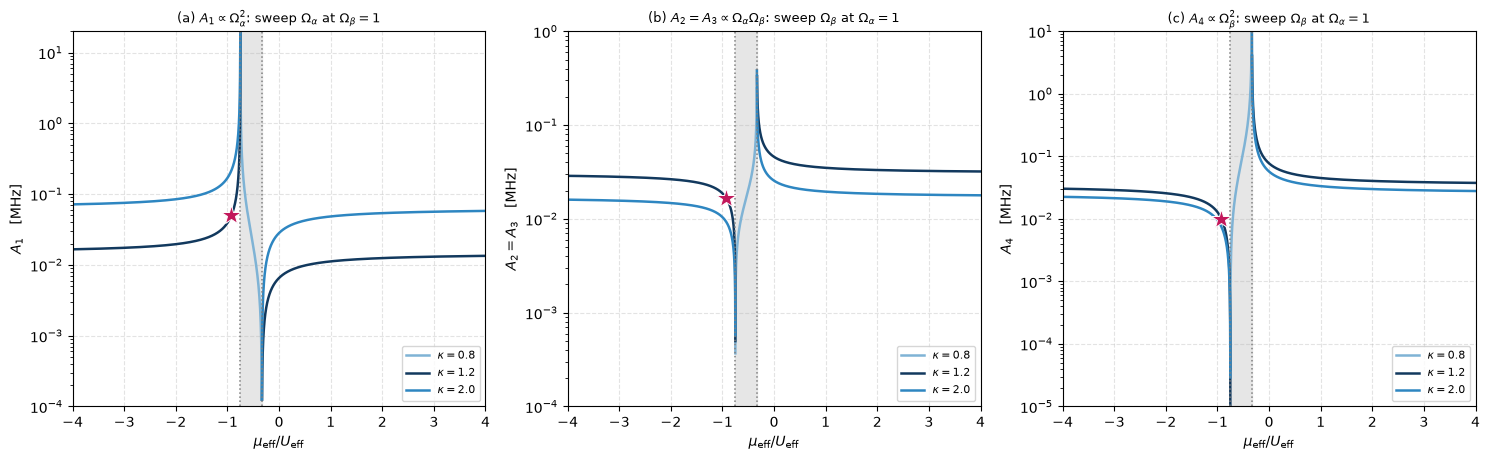

In [7]:
import matplotlib
# Inline backend selected in notebook setup.
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(15.0, 4.7))


def brs(m, jump=1.0):
  cut = np.where(np.abs(np.diff(m)) > jump)[0]
  return [s for s in np.split(np.arange(m.size), cut + 1) if s.size > 1]


# (a) A_1, sweeping Om_a at Om_b = 1
ax = axs[0]
for k in KAPPAS:
  oa = np.geomspace(0.05, 20.0, 40000)
  m = np.array([muU_x((1.0 / oa[i]**2) * Sigma(k)) for i in range(oa.size)])
  y = oa**2 * K1
  f = True
  for s in brs(m):
    ax.plot(m[s], y[s], color=COL[k], lw=1.8,
            label=(r'$\kappa=%.1f$' % k) if f else None)
    f = False
ax.plot([muU_x(Sigma(KMAIN))], [K1], '*', color='#c2185b', ms=15, zorder=5,
        markeredgecolor='w', markeredgewidth=0.7)
ax.set_ylabel(r'$A_1$   [MHz]')
ax.set_title(r'(a) $A_1\propto\Omega_\alpha^2$: sweep $\Omega_\alpha$ '
             r'at $\Omega_\beta=1$', fontsize=9.5)

# (b) A_2 = A_3 and (c) A_4, sweeping Om_b at Om_a = 1
for idx, (lab, fun, ttl) in enumerate([
    (r'$A_2=A_3$   [MHz]',
     lambda ob, k: ob * K2 * abs(jv(N_RES, k)),
     r'(b) $A_2=A_3\propto\Omega_\alpha\Omega_\beta$: sweep $\Omega_\beta$'),
    (r'$A_4$   [MHz]',
     lambda ob, k: ob**2 * abs(Sigma4(k)),
     r'(c) $A_4\propto\Omega_\beta^2$: sweep $\Omega_\beta$')]):
  ax = axs[idx + 1]
  for k in KAPPAS:
    ob = np.geomspace(0.03, 20.0, 40000)
    m = np.array([muU_x(ob[i]**2 * Sigma(k)) for i in range(ob.size)])
    y = fun(ob, k)
    f = True
    for s in brs(m):
      ax.plot(m[s], y[s], color=COL[k], lw=1.8,
              label=(r'$\kappa=%.1f$' % k) if f else None)
      f = False
  y0 = fun(1.0, KMAIN)
  ax.plot([muU_x(Sigma(KMAIN))], [y0], '*', color='#c2185b', ms=15, zorder=5,
          markeredgecolor='w', markeredgewidth=0.7)
  ax.set_ylabel(lab)
  ax.set_title(ttl + r' at $\Omega_\alpha=1$', fontsize=9.5)

for ax in axs:
  ax.axvline(-1.0 / 3.0, color='gray', ls=':', lw=1.1)
  ax.axvline(-0.75, color='gray', ls=':', lw=1.1)
  ax.axvspan(-0.75, -1.0 / 3.0, color='0.9', zorder=0)
  ax.set_xlim(-4, 4)
  ax.set_yscale('log')
  ax.set_xlabel(r'$\mu_{\mathrm{eff}}/U_{\mathrm{eff}}$')
  ax.legend(fontsize=8, loc='lower right')
  ax.grid(True, ls='--', alpha=0.35)
axs[0].set_ylim(1e-4, 2e1)
axs[1].set_ylim(1e-4, 1e0)
axs[2].set_ylim(1e-5, 1e1)

fig.tight_layout()
plt.show()

## 5. Chemical potential against normalized amplitudes

**Thesis source:** Section 4.2, pp. 31–32, Figure 7. Explanations below paraphrase this passage.

Figure 7 places $A_i/U_{\mathrm{eff}}$ on the horizontal axis and the bare $\mu_{\mathrm{eff}}$ on the vertical axis. The source uses fixed $\Omega_\alpha=1$ and sweeps $r$ for each modulation index. `curves` returns the four normalized amplitudes, their effective chemical-potential ratio, and the bare chemical potential.

**Code source:** [`mu_vs_A_over_U.py`, lines 67–67](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/mu_vs_A_over_U.py#L67-L67).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [8]:
OM_A = 1.0                      # Rabi scale (MHz); the curves slide as lam^2

**Code source:** [`mu_vs_A_over_U.py`, lines 84–94](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/mu_vs_A_over_U.py#L84-L94).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [9]:
def curves(k, r):
  """A_i/U_eff (4), mu_eff/U_eff, mu_eff [MHz] at Om_a = OM_A."""
  S, S4 = Sigma(k), Sigma4(k)
  x = r * S
  den = 3.0 * x - B_
  a1 = K1 / den
  a2 = np.sqrt(r) * K2 * abs(jv(N_RES, k)) / den
  a4 = r * abs(S4) / den
  mu_over_U = (A_ - x) / den
  mu = OM_A**2 * (A_ - x)
  return (a1, a2, a2, a4), mu_over_U, mu

**Code source:** [`mu_vs_A_over_U.py`, lines 139–194](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/mu_vs_A_over_U.py#L139-L194).

**Notebook changes:** Original formula calculations, sweep ranges and plotting code; inline display replaces export.

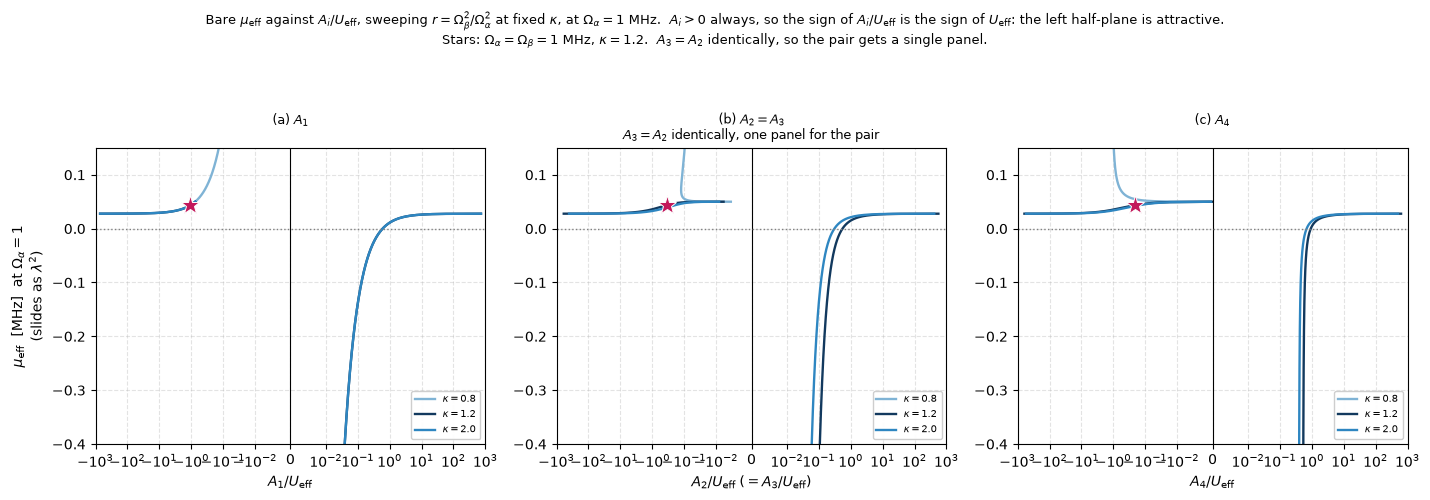

In [10]:
import matplotlib
# Inline backend selected in notebook setup.
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(14.4, 5.0))
COLS = [(0, r'$A_1/U_{\mathrm{eff}}$', r'$A_1$'),
        (1, r'$A_2/U_{\mathrm{eff}}\;(=A_3/U_{\mathrm{eff}})$', r'$A_2=A_3$'),
        (3, r'$A_4/U_{\mathrm{eff}}$', r'$A_4$')]
rr = np.geomspace(1e-3, 1e3, 200000)


def brs(v, jump):
  cut = np.where(np.abs(np.diff(v)) > jump)[0]
  return [s for s in np.split(np.arange(v.size), cut + 1) if s.size > 1]


for c, (i, xlab, short) in enumerate(COLS):
  ax = axs[c]
  for k in KAPPAS:
    (A, mU, mu) = curves(k, rr)
    xv = A[i]
    f = True
    for sg in brs(xv, 50.0):
      ax.plot(xv[sg], mu[sg], color=COL[k], lw=1.7,
              label=(r'$\kappa=%.1f$' % k) if f else None)
      f = False
  (A0, mU0, mu0) = curves(KMAIN, 1.0)
  ax.plot([A0[i]], [mu0], '*', color='#c2185b', ms=14, zorder=6,
          markeredgecolor='w', markeredgewidth=0.7)
  ax.axvline(0.0, color='k', lw=0.8)
  ax.axhline(0.0, color='gray', ls=':', lw=1.0)
  ax.set_xscale('symlog', linthresh=1e-2)
  ax.set_xlim(-1e3, 1e3)
  ax.set_ylim(-0.4 * OM_A**2, 0.15 * OM_A**2)
  ax.set_xlabel(xlab)
  if c == 0:
    ax.set_ylabel(r'$\mu_{\mathrm{eff}}$  [MHz]  at $\Omega_\alpha=%g$' % OM_A
                  + '\n' + r'(slides as $\lambda^2$)')
  ax.set_title((r'(%s) ' % 'abc'[c]) + short
               + ('\n' r'$A_3=A_2$ identically, one panel for the pair'
                  if c == 1 else '\n '), fontsize=9)
  ax.legend(fontsize=7, loc='lower right', framealpha=0.95)
  ax.grid(True, ls='--', alpha=0.35)

fig.suptitle(r'Bare $\mu_{\mathrm{eff}}$ against $A_i/U_{\mathrm{eff}}$, '
             r'sweeping $r=\Omega_\beta^2/\Omega_\alpha^2$ at fixed $\kappa$, '
             + (r'at $\Omega_\alpha=%g$ MHz.  ' % OM_A) +
             r'$A_i>0$ always, so the sign of $A_i/U_{\mathrm{eff}}$ is the '
             r'sign of $U_{\mathrm{eff}}$: the left half-plane is attractive.'
             + '\n' + (r'Stars: $\Omega_\alpha=\Omega_\beta=%g$ MHz, '
                       r'$\kappa=1.2$.  ' % OM_A) +
             r'$A_3=A_2$ identically, so the pair gets a single panel.',
             fontsize=9.5, y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.925])
plt.show()

## Source and reproduction record

The original scripts and saved data are unchanged. See [SOURCE_MAP.md](SOURCE_MAP.md) for the thesis-to-code map and [VALIDATION.md](VALIDATION.md) for the checks performed on this revision.